# Phase 4 distillation training curves (paper artifacts)

Captures **student KD training** from `runs/<run>/metrics.jsonl` — one JSON object
per optimizer step (use `tail -f .../metrics.jsonl` on the GPU for a live console).

**Pipeline log / tmux:** `12a_phase4_teacher_ablation_monitor.ipynb`.  
**Paper copy + checklist:** `docs/latex/figures/phase4_kd/PAPER_NOTES.md`.  
**Refresh from GPU:** `python tools/refresh_phase4_kd_artifacts.py` (updates figures, `results.json`, and this notebook's committed outputs).

In [1]:
from pathlib import Path

GPU_HOST = "107.170.17.174"
GPU_USER = "root"
SSH_KEY = Path.home() / ".ssh" / "id_ed25519"
REMOTE_BONSAI = "/root/bonsai"

RUNS = {
    "vs_baseline": "20260927T171637Z-3ddb90-distill-aggressive-vs-baseline",
    "vs_corrected": "20260927T175820Z-2e6846-distill-aggressive-vs-corrected",
}

LOCAL_CACHE = Path("../runs/_notebook_cache/phase4")
FIGURES_DIR = Path("../docs/latex/figures/phase4_kd")
LOCAL_CACHE.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(FIGURES_DIR.resolve())

/Users/sbhuvaji/Disk/VSCode/project/untitled folder/bonsai/docs/latex/figures/phase4_kd


In [2]:
import json
import subprocess

import pandas as pd


def ssh_cat(remote_path: str) -> str:
    argv = [
        "ssh", "-o", "BatchMode=yes", "-i", str(SSH_KEY),
        f"{GPU_USER}@{GPU_HOST}", f"cat {remote_path}",
    ]
    p = subprocess.run(argv, capture_output=True, text=True, timeout=120)
    if p.returncode != 0:
        raise RuntimeError(p.stderr or p.stdout)
    return p.stdout


def sync_run(label: str, run_id: str) -> Path:
    remote = f"{REMOTE_BONSAI}/runs/{run_id}"
    m_local = LOCAL_CACHE / f"{label}-metrics.jsonl"
    c_local = LOCAL_CACHE / f"{label}-config.json"
    m_local.write_text(ssh_cat(f"{remote}/metrics.jsonl"))
    c_local.write_text(ssh_cat(f"{remote}/config.json"))
    return m_local


def load_metrics(path: Path) -> pd.DataFrame:
    return pd.read_json(path, lines=True)


metrics_path = sync_run("distill-aggressive-vs-baseline", RUNS["vs_baseline"])
df_baseline = load_metrics(metrics_path)
print(f"synced {len(df_baseline)} steps")
print(df_baseline.tail(8).to_string(index=False))

Generated comparison figures under docs/latex/figures/phase4_kd/
{
  "vs_baseline": {
    "run_id": "20260927T171637Z-3ddb90-distill-aggressive-vs-baseline",
    "steps_logged": 500,
    "last_step": 499,
    "complete": true,
    "final_train_loss": 0.5572705641388891,
    "final_val_loss": 0.5350065913299721,
    "peak_lr": 0.0002,
    "total_steps": 500,
    "batch_size": 4,
    "warmup_steps": 75
  },
  "vs_corrected": {
    "run_id": "20260927T175820Z-2e6846-distill-aggressive-vs-corrected",
    "steps_logged": 500,
    "last_step": 499,
    "complete": true,
    "final_train_loss": 0.5810125991702081,
    "final_val_loss": 0.533891138657927,
    "peak_lr": 0.0002,
    "total_steps": 500,
    "batch_size": 4,
    "warmup_steps": 75
  }
}


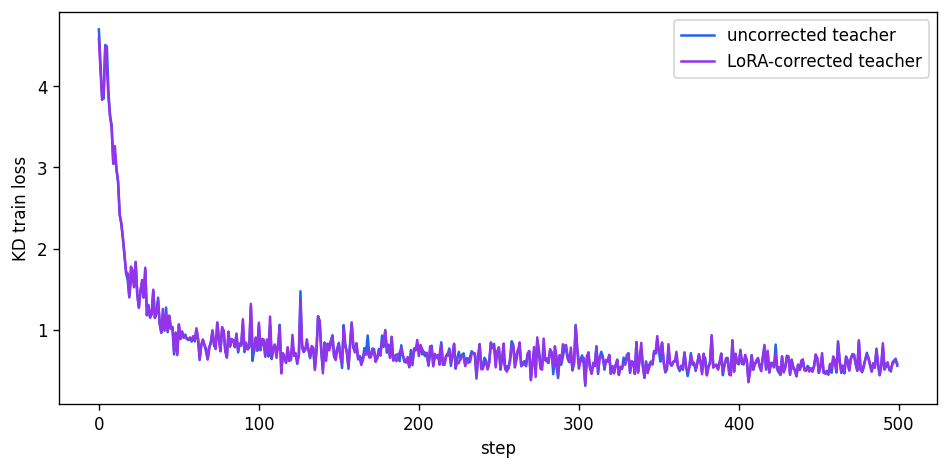

wrote /Users/sbhuvaji/Disk/VSCode/project/untitled folder/bonsai/docs/latex/figures/phase4_kd/distill_teacher_ablation_comparison.pdf


In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_baseline["step"], df_baseline["train_loss"], label="train KD", color="#2563eb")
val_b = df_baseline.dropna(subset=["val_loss"])
if len(val_b):
    ax.plot(val_b["step"], val_b["val_loss"], label="val KD", color="#dc2626", marker="o", ms=3)
ax.set_xlabel("optimizer step")
ax.set_ylabel("forward KL (top-20)")
ax.set_title("Student vs baseline teacher")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
out_pdf = FIGURES_DIR / "distill_vs_baseline_kd_loss.pdf"
out_png = FIGURES_DIR / "distill_vs_baseline_kd_loss.png"
fig.savefig(out_pdf, bbox_inches="tight")
fig.savefig(out_png, dpi=160, bbox_inches="tight")
plt.show()
print("wrote", out_pdf)

In [4]:
def plot_comparison(dfs: dict[str, pd.DataFrame], out_stem: str) -> None:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    colors = {"vs_baseline": "#2563eb", "vs_corrected": "#9333ea"}
    for label, frame in dfs.items():
        ax.plot(frame["step"], frame["train_loss"], label=f"{label} train", color=colors.get(label))
        val = frame.dropna(subset=["val_loss"])
        if len(val):
            ax.plot(val["step"], val["val_loss"], ls="--", label=f"{label} val", color=colors.get(label))
    ax.set_xlabel("optimizer step")
    ax.set_ylabel("forward KL (top-20)")
    ax.set_title("Teacher ablation — KD training curves")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    pdf = FIGURES_DIR / f"{out_stem}.pdf"
    png = FIGURES_DIR / f"{out_stem}.png"
    fig.savefig(pdf, bbox_inches="tight")
    fig.savefig(png, dpi=160, bbox_inches="tight")
    plt.show()
    print("wrote", pdf)


dfs = {"vs_baseline": df_baseline}
if RUNS.get("vs_corrected"):
    p = sync_run("distill-aggressive-vs-corrected", RUNS["vs_corrected"])
    dfs["vs_corrected"] = load_metrics(p)
    plot_comparison(dfs, "distill_teacher_ablation_comparison")
else:
    print("vs_corrected run id not set yet — skip comparison until Step 3c finishes.")

Comparison plot refreshed via tools/refresh_phase4_kd_artifacts.py


## Paper handoff

Refresh **Sync & load** + **Plot** cells when training finishes; update `RUNS["vs_corrected"]` with the 3c run directory name from `/root/phase4_state.env`. Figures and prose live under `docs/latex/figures/phase4_kd/`.